# 01 — Exploration

**Question:** which factors go together with skipping a track? The answers shape the label, the features and the model (notebook 02).

**Data:** `streams_clean.parquet`, music plays since 2020 (`src/load_data.py`). Rates use only rows with an observed outcome: plays that end with an interruption (logout, remote device, app crash, ...) are censored. Two skip flags:
- `skip`: Spotify's definition, I left the track by choice (`fwdbtn` forward, `backbtn` back, `endplay` another track chosen);
- `skip_fwd`: forward button only (`fwdbtn`). Here `endplay` and `backbtn` count as 0; the final label in `src/features.py` treats them as censored (section *`endplay` and the queue*).

Tables report the rate, the number of observed outcomes `n` and the half-width `ci` of the 95% confidence interval, $1.96\sqrt{p(1-p)/n}$.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss, roc_auc_score

sys.path.append("../src")
from features import OBSERVED, ROOT, SESSION_GAP_MIN, platform_group

df = pd.read_parquet(ROOT / "data" / "streams_clean.parquet")

# Skip flags as float, NaN on censored rows: these stay in df (needed for counts and sessions),
# but mean() ignores them, so rates use observed outcomes only
df["observed"] = df["reason_end"].isin(OBSERVED)
skip_ends = ["fwdbtn", "endplay", "backbtn"]
df["skip"] = df["reason_end"].isin(skip_ends).astype(float).where(df["observed"])
df["skip_fwd"] = (df["reason_end"] == "fwdbtn").astype(float).where(df["observed"])
print(f"Rows: {len(df)}, with an observed outcome: {df['observed'].mean():.1%}")
print(f"Skip rate: {df['skip'].mean():.1%} (fwdbtn only: {df['skip_fwd'].mean():.1%})")

# ts is in UTC: local time of Italy and Germany (same time zone)
df["ts_local"] = df["ts"].dt.tz_convert("Europe/Rome")
df["hour"] = df["ts_local"].dt.hour
df["weekday"] = df["ts_local"].dt.day_of_week  # 0 = Monday, 6 = Sunday


def rate_table(data, by, col="skip", dropna=True):
    """Rate of `col`, number of observed outcomes and 95% CI half-width for each group."""
    t = data.groupby(by, observed=True, dropna=dropna)[col].agg(rate="mean", n="count")
    t["ci"] = 1.96 * np.sqrt(t["rate"] * (1 - t["rate"]) / t["n"])
    return t.round(3)

Rows: 111016, with an observed outcome: 90.5%
Skip rate: 39.1% (fwdbtn only: 26.7%)


## Hour, weekday and shuffle

       rate     n     ci
hour                    
0     0.480  4156  0.015
1     0.419  1979  0.022
2     0.285   814  0.031
3     0.256   434  0.041
4     0.129   348  0.035
5     0.276   612  0.035
6     0.304   970  0.029
7     0.356  3216  0.017
8     0.302  3491  0.015
9     0.308  3331  0.016
10    0.303  4046  0.014
11    0.333  4614  0.014
12    0.297  4887  0.013
13    0.378  5254  0.013
14    0.372  6044  0.012
15    0.381  5818  0.012
16    0.371  6436  0.012
17    0.370  6302  0.012
18    0.376  7105  0.011
19    0.424  7450  0.011
20    0.430  6342  0.012
21    0.482  5911  0.013
22    0.499  5038  0.014
23    0.523  5884  0.013


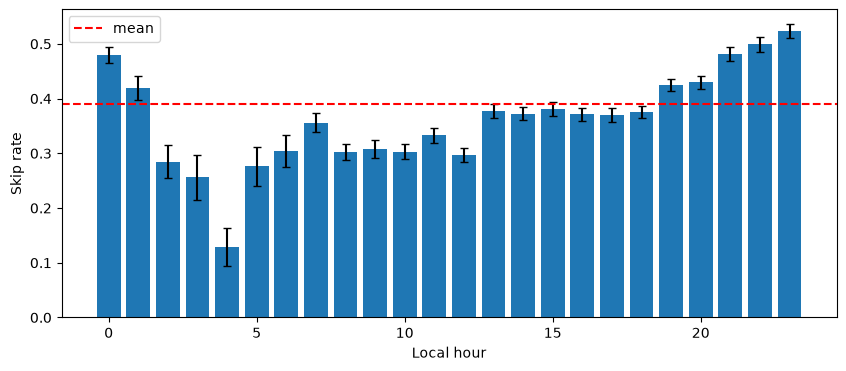

In [2]:
by_hour = rate_table(df, "hour")
print(by_hour)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_hour.index, by_hour["rate"], yerr=by_hour["ci"], capsize=3)
ax.axhline(df["skip"].mean(), color="red", linestyle="--", label="mean")
ax.set_xlabel("Local hour")
ax.set_ylabel("Skip rate")
ax.legend()
plt.show()

In [3]:
for col in ["weekday", "shuffle"]:
    print(rate_table(df, col), "\n")

          rate      n     ci
weekday                     
0        0.368  14005  0.008
1        0.356  12576  0.008
2        0.369  13991  0.008
3        0.366  14498  0.008
4        0.394  15785  0.008
5        0.450  17004  0.007
6        0.419  12623  0.009 

          rate      n     ci
shuffle                     
False    0.366  25689  0.006
True     0.399  74793  0.004 



## Previous plays of the track

In [4]:
# For each row: how many times the track had appeared BEFORE (0, 1, 2, ...)
df["prev_plays"] = df.groupby("track_uri").cumcount()

bins = [-1, 0, 1, 4, 9, 19, 49, 99, np.inf]
labels = ["0", "1", "2-4", "5-9", "10-19", "20-49", "50-99", "100+"]
df["prev_bin"] = pd.cut(df["prev_plays"], bins=bins, labels=labels)
print(rate_table(df, "prev_bin"))

           rate      n     ci
prev_bin                     
0         0.336  18500  0.007
1         0.334   9419  0.010
2-4       0.376  15106  0.008
5-9       0.405  14437  0.008
10-19     0.430  17130  0.007
20-49     0.442  18895  0.007
50-99     0.388   5916  0.012
100+      0.366   1079  0.029


In [5]:
# Same curve with and without shuffle
grid = dict(index="prev_bin", columns="shuffle", values="skip", observed=True)
rate = df.pivot_table(aggfunc="mean", **grid)
n = df.pivot_table(aggfunc="count", **grid)
print(rate.round(3), "\n")
print(n)

shuffle   False  True 
prev_bin              
0         0.343  0.330
1         0.333  0.335
2-4       0.355  0.384
5-9       0.375  0.414
10-19     0.387  0.439
20-49     0.446  0.441
50-99     0.414  0.385
100+      0.331  0.371 

shuffle   False  True 
prev_bin              
0          7777  10723
1          3384   6035
2-4        4445  10661
5-9        3393  11044
10-19      3025  14105
20-49      2821  16074
50-99       723   5193
100+        121    958


## Sessions, position in the session and previous skip

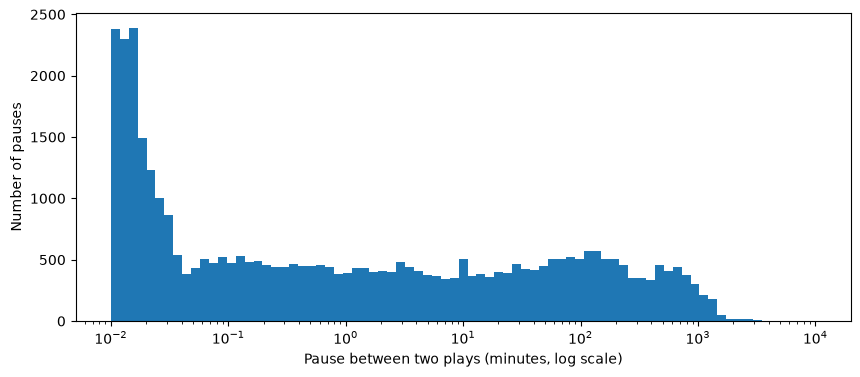

pauses >  2 min: 14.2%
pauses >  5 min: 12.2%
pauses > 10 min: 10.9%
pauses > 20 min: 9.5%
pauses > 30 min: 8.6%
pauses > 60 min: 7.0%


In [6]:
# Start of each play = end (ts) minus time played
df["start"] = df["ts"] - pd.to_timedelta(df["ms_played"], unit="ms")

# Pause = start of this play minus end of the previous one, in minutes
df["gap_min"] = (df["start"] - df["ts"].shift()).dt.total_seconds() / 60

gaps = df["gap_min"].dropna()
gaps = gaps[gaps > 0]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(gaps, bins=np.logspace(-2, 4, 80))
ax.set_xscale("log")
ax.set_xlabel("Pause between two plays (minutes, log scale)")
ax.set_ylabel("Number of pauses")
plt.show()

for t in [2, 5, 10, 20, 30, 60]:
    print(f"pauses > {t:>2} min: {(df['gap_min'] > t).mean():.1%}")

In [7]:
# New session after a pause longer than SESSION_GAP_MIN = 30 minutes (threshold checked at the end)
df["session_id"] = (df["gap_min"] > SESSION_GAP_MIN).cumsum()
df["pos"] = df.groupby("session_id").cumcount()  # 0 = first track of the session
# Skip of the previous track in the same session
df["prev_skip"] = df.groupby("session_id")["skip"].shift()

print("Sessions:", df["session_id"].nunique())
print(df.groupby("session_id").size().describe().round(1), "\n")

bins = [-1, 0, 1, 2, 4, 9, 19, 49, np.inf]
labels = ["1", "2", "3", "4-5", "6-10", "11-20", "21-50", "51+"]
df["pos_bin"] = pd.cut(df["pos"], bins=bins, labels=labels)
print(rate_table(df, "pos_bin"), "\n")
print(rate_table(df, "prev_skip", dropna=False))

Sessions: 9583
count    9583.0
mean       11.6
std        16.5
min         1.0
25%         2.0
50%         7.0
75%        14.0
max       271.0
dtype: float64 

          rate      n     ci
pos_bin                     
1        0.506   4536  0.015
2        0.401   6855  0.012
3        0.356   6686  0.011
4-5      0.335  11933  0.008
6-10     0.335  21872  0.006
11-20    0.361  22166  0.006
21-50    0.432  18489  0.007
51+      0.571   7945  0.011 

            rate      n     ci
prev_skip                     
0.0        0.176  54173  0.003
1.0        0.692  36193  0.005
NaN        0.463  10116  0.010


## Wear: days since the last play

In [8]:
# Days since the previous play of the same track
df["days_since_last"] = df.groupby("track_uri")["ts"].diff().dt.total_seconds() / 86400

bins = [0, 1 / 24, 1, 7, 30, 90, 365, np.inf]
labels = ["<1h", "1h–1d", "1–7d", "7–30d", "30–90d", "90–365d", ">1 year"]
df["dsl_bin"] = pd.cut(df["days_since_last"], bins=bins, labels=labels, right=False)
df["dsl_bin"] = df["dsl_bin"].cat.add_categories("first play").fillna("first play")
print(rate_table(df, "dsl_bin"))

             rate      n     ci
dsl_bin                        
<1h         0.517   7046  0.012
1h–1d       0.409   9420  0.010
1–7d        0.422  18811  0.007
7–30d       0.393  19129  0.007
30–90d      0.370  13028  0.008
90–365d     0.367  10673  0.009
>1 year     0.360   3875  0.015
first play  0.336  18500  0.007


In [9]:
# Recency (columns) at equal number of previous plays (rows)
grid = dict(index="prev_bin", columns="dsl_bin", values="skip", observed=True)
rate = df.pivot_table(aggfunc="mean", **grid)
n = df.pivot_table(aggfunc="count", **grid)
print(rate.round(3), "\n")
print(n)

dsl_bin     <1h  1h–1d   1–7d  7–30d  30–90d  90–365d  >1 year  first play
prev_bin                                                                  
0           NaN    NaN    NaN    NaN     NaN      NaN      NaN       0.336
1         0.500  0.287  0.278  0.324   0.323    0.332    0.328         NaN
2-4       0.496  0.358  0.369  0.362   0.364    0.341    0.363         NaN
5-9       0.511  0.400  0.417  0.407   0.360    0.371    0.367         NaN
10-19     0.549  0.485  0.461  0.408   0.377    0.385    0.390         NaN
20-49     0.548  0.562  0.485  0.418   0.395    0.380    0.385         NaN
50-99     0.511  0.465  0.410  0.370   0.344    0.393    0.314         NaN
100+      0.491  0.431  0.409  0.309   0.373    0.378    0.333         NaN 

dsl_bin      <1h   1h–1d    1–7d   7–30d  30–90d  90–365d  >1 year  first play
prev_bin                                                                      
0            NaN     NaN     NaN     NaN     NaN      NaN      NaN     18500.0
1         1

## Drift over time

          rate      n  shuffle_share     ci  rate_shuffle
quarter                                                  
2020Q1   0.273     11          0.000  0.263           NaN
2020Q2   0.427    157          0.000  0.077           NaN
2020Q3   0.534   4401          0.600  0.015         0.527
2020Q4   0.580  10896          0.646  0.009         0.649
2021Q1   0.508   8881          0.869  0.010         0.523
2021Q2   0.480   3862          0.758  0.016         0.476
2021Q3   0.453   2370          0.803  0.020         0.449
2021Q4   0.245   2589          0.804  0.017         0.218
2022Q1   0.283   2830          0.684  0.017         0.281
2022Q2   0.424   2568          0.724  0.019         0.454
2022Q3   0.472   2136          0.860  0.021         0.476
2022Q4   0.398   3306          0.741  0.017         0.444
2023Q1   0.396   2646          0.752  0.019         0.424
2023Q2   0.412   2088          0.706  0.021         0.428
2023Q3   0.376   2665          0.646  0.018         0.411
2023Q4   0.231

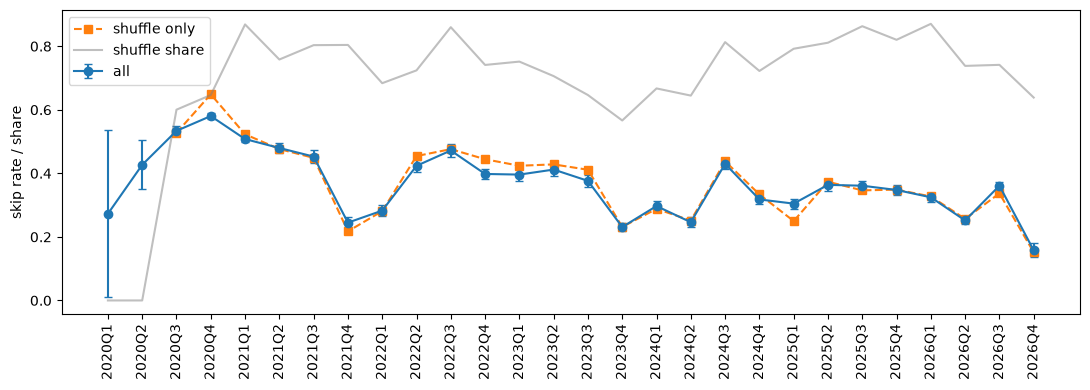

In [10]:
# Quarter of each play (time zone removed to avoid a pandas warning)
df["quarter"] = df["ts"].dt.tz_localize(None).dt.to_period("Q")

q = df.groupby("quarter").agg(
    rate=("skip", "mean"), n=("skip", "count"), shuffle_share=("shuffle", "mean")
)
q["ci"] = 1.96 * np.sqrt(q["rate"] * (1 - q["rate"]) / q["n"])
q["rate_shuffle"] = df[df["shuffle"]].groupby("quarter")["skip"].mean()
print(q.round(3))

fig, ax = plt.subplots(figsize=(11, 4))
x = q.index.astype(str)
ax.errorbar(x, q["rate"], yerr=q["ci"], marker="o", capsize=3, label="all")
ax.plot(x, q["rate_shuffle"], marker="s", linestyle="--", label="shuffle only")
ax.plot(x, q["shuffle_share"], color="grey", alpha=0.5, label="shuffle share")
ax.set_ylabel("skip rate / share")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
recent = df[df["quarter"] >= pd.Period("2025Q3", freq="Q")]

# End reasons per quarter (each row sums to 1)
print(pd.crosstab(recent["quarter"], recent["reason_end"], normalize="index").round(3), "\n")

# Skip rate and number of plays per quarter and country
print(recent.groupby(["quarter", "country"])["skip"].agg(rate="mean", n="count").round(3))

reason_end  backbtn  endplay  fwdbtn  logout  remote  switched-to-video  \
quarter                                                                   
2025Q3        0.012    0.090   0.237   0.006   0.008              0.000   
2025Q4        0.009    0.090   0.212   0.008   0.034              0.000   
2026Q1        0.004    0.078   0.217   0.004   0.024              0.000   
2026Q2        0.004    0.104   0.125   0.003   0.025              0.000   
2026Q3        0.007    0.159   0.171   0.006   0.011              0.002   
2026Q4        0.004    0.096   0.044   0.001   0.018              0.001   

reason_end  trackdone  trackerror  unexpected-exit  \
quarter                                              
2025Q3          0.600       0.001            0.001   
2025Q4          0.584       0.003            0.001   
2026Q1          0.624       0.002            0.001   
2026Q2          0.694       0.006            0.003   
2026Q3          0.596       0.002            0.005   
2026Q4          0.770

In [12]:
# Duration of the complete plays per quarter (5th percentile and median, seconds)
td = recent[recent["reason_end"] == "trackdone"]
print((td.groupby("quarter")["ms_played"].quantile([0.05, 0.5]).unstack() / 1000).round(0))

          0.05   0.50
quarter              
2025Q3   114.0  183.0
2025Q4   103.0  186.0
2026Q1   119.0  190.0
2026Q2   113.0  182.0
2026Q3   121.0  192.0
2026Q4   100.0  188.0


## Full vs recent track history

Past skip rate of the track with shrinkage, $(\text{past skips} + \alpha p_0)/(\text{past outcomes} + \alpha)$, over the whole history or over the last 90 days.

In [13]:
alpha = 5  # same strength as ALPHA in features.py
p0 = df["skip"].mean()  # fine for exploring; features.py uses only the past
df["skip0"] = df["skip"].fillna(0)  # for sums: a censored row adds no skip...
df["obs_f"] = df["observed"].astype(float)

g = df.groupby("track_uri")
df["n_prev"] = g["obs_f"].cumsum() - df["obs_f"]  # ...and does not count as a past outcome
df["skips_prev"] = g["skip0"].cumsum() - df["skip0"]
df["rate_all"] = (df["skips_prev"] + alpha * p0) / (df["n_prev"] + alpha)

# Last 90 days: moving time window per track, current play excluded
r = df.groupby("track_uri").rolling("90D", on="ts", closed="left")["skip"]

# The result is sorted by track, then by time: rebuild the row order of df
order = df.sort_values("track_uri", kind="stable").index
df["s90"] = pd.Series(r.sum().to_numpy(), index=order).fillna(0)
df["n90"] = pd.Series(r.count().to_numpy(), index=order).fillna(0)
df["rate_90"] = (df["s90"] + alpha * p0) / (df["n90"] + alpha)

# Consistency: the last 90 days cannot hold more outcomes than the whole history
assert (df["n90"] <= df["n_prev"]).all()

In [14]:
start = pd.Timestamp("2021-07-01", tz="UTC")
ev = df[(df["ts"] >= start) & (df["n_prev"] >= 1) & df["observed"]]

groups = [("all (n_prev >= 1)", ev), ("with plays in the last 90 days", ev[ev["n90"] >= 1])]
for name, sub in groups:
    print(f"{name}: n = {len(sub)}")
    for col in ["rate_all", "rate_90"]:
        auc, ll = roc_auc_score(sub["skip"], sub[col]), log_loss(sub["skip"], sub[col])
        print(f"  {col}:  AUC = {auc:.3f}   log-loss = {ll:.4f}")

all (n_prev >= 1): n = 55761
  rate_all:  AUC = 0.606   log-loss = 0.6380
  rate_90:  AUC = 0.580   log-loss = 0.6386
with plays in the last 90 days: n = 40781
  rate_all:  AUC = 0.608   log-loss = 0.6321
  rate_90:  AUC = 0.591   log-loss = 0.6321


## How a play starts, and resumed plays

In [15]:
s = rate_table(df, "reason_start").sort_values("n", ascending=False)
s["share"] = (s["n"] / df["observed"].sum()).round(3)
print(s, "\n")

# reason_start by days since the last play (each row sums to 1)
print(pd.crosstab(df["dsl_bin"], df["reason_start"], normalize="index").round(2))

                    rate      n     ci  share
reason_start                                 
trackdone          0.186  55429  0.003  0.552
fwdbtn             0.729  25574  0.005  0.255
playbtn            0.477   8719  0.010  0.087
clickrow           0.708   5123  0.012  0.051
remote             0.337   2495  0.019  0.025
appload            0.396   1802  0.023  0.018
backbtn            0.747   1011  0.027  0.010
unknown            0.995    206  0.009  0.002
trackerror         0.431    102  0.096  0.001
switched-to-audio  0.238     21  0.182  0.000 

reason_start  appload  backbtn  clickrow  fwdbtn  playbtn  remote  \
dsl_bin                                                             
<1h              0.16     0.11      0.10    0.14     0.04    0.25   
1h–1d            0.06     0.01      0.08    0.23     0.08    0.03   
1–7d             0.00     0.00      0.05    0.31     0.10    0.01   
7–30d            0.00     0.00      0.03    0.29     0.09    0.01   
30–90d           0.00     0.00  

In [16]:
same_prev = df["track_uri"].eq(df["track_uri"].shift())
prev_end = df["reason_end"].shift()
technical = ["appload", "remote", "playbtn", "trackerror", "unknown"]

resume = same_prev & df["reason_start"].isin(technical)
restart = same_prev & (df["reason_start"] == "backbtn")

print(f"Resumes: {resume.sum()} rows ({resume.mean():.1%})")
print(f"Restarts with the back button: {restart.sum()} rows ({restart.mean():.1%})")
print(f"Share of resumes in the <1h bin: {resume[df['dsl_bin'] == '<1h'].mean():.1%}\n")

# How the previous piece had ended, by type of resume
print(pd.crosstab(prev_end[resume], df.loc[resume, "reason_start"]))

Resumes: 4003 rows (3.6%)
Restarts with the back button: 48 rows (0.0%)
Share of resumes in the <1h bin: 41.5%

reason_start                  appload  playbtn  remote  trackerror  unknown
reason_end                                                                 
backbtn                             0        0       1           0        0
endplay                             3      113      38           2       26
fwdbtn                              1        3      13           0        0
logout                            678       14      79           0        3
remote                             38        9    1522           0        0
trackdone                           6       12      60           0        0
trackerror                          2        0       0          58        0
unexpected-exit                    11        1      10           0        1
unexpected-exit-while-paused     1021        3      63           0        0
unknown                             8        1     2

## Device

In [17]:
# Raw platform strings, device identifiers masked
platforms = df["platform"].str.replace(r"[0-9a-f]{32}", "<id>", regex=True)
print("Distinct values:", df["platform"].nunique(), "\n")
print(platforms.value_counts().head(40))

Distinct values: 62 

platform
ios                                                  51971
not_applicable                                        9378
iOS 14.2 (iPhone12,1)                                 5950
iOS 14.4 (iPhone12,1)                                 4059
Partner amazon_salmon Amazon;Echo_Dot;<id>;;tpapi     3819
iOS 14.0.1 (iPhone12,1)                               3273
iOS 14.4.2 (iPhone12,1)                               3241
Partner SCEI sony_tv;ps4;<id>;;tpapi                  3120
iOS 14.3 (iPhone12,1)                                 2742
iOS 13.5.1 (iPhone12,1)                               2439
iOS 14.6 (iPhone12,1)                                 2346
iOS 15.1 (iPhone12,1)                                 2018
osx                                                   1720
iOS 15.5 (iPhone12,1)                                 1531
iOS 15.4.1 (iPhone12,1)                               1402
Partner amazon_fireos Amazon;Echo_Dot;<id>;;tpapi     1038
iOS 15.3.1 (iPhone12,1)  

In [18]:
# platform_group (src/features.py): rules from the most specific to the most general
df["device"] = df["platform"].map(platform_group)

# 1. Plays per category, and what ended up in "other" (so as not to miss important cases)
print(df["device"].value_counts(), "\n")
print(df.loc[df["device"] == "other", "platform"].value_counts(), "\n")

# 2. Skip rate per device
print(rate_table(df, "device"), "\n")

# 3. When the categories appear (in particular "unknown")
print(pd.crosstab(df["ts"].dt.year, df["device"]))

device
phone         89397
unknown        9378
speaker        4857
tv_console     3834
computer       3550
Name: count, dtype: int64 

Series([], Name: count, dtype: int64) 

             rate      n     ci
device                         
computer    0.186   3035  0.014
phone       0.424  81308  0.003
speaker     0.333   4280  0.014
tv_console  0.486   3484  0.017
unknown     0.132   8375  0.007 

device  computer  phone  speaker  tv_console  unknown
ts                                                   
2020         686  11506     2790        2601        0
2021        1111  17368      831         742        0
2022          39  10018     1236         261      553
2023         202   9804        0           0     1912
2024         246  11848        0          54     2738
2025         257  11437        0         123     1829
2026        1009  17416        0          53     2346


## `endplay` and the queue

In [19]:
obs = df[df["observed"]].copy()
obs["first"] = obs["pos"] == 0

# End reason: first track of the session or not, with or without shuffle (each row sums to 1)
ends = pd.crosstab([obs["first"], obs["shuffle"]], obs["reason_end"], normalize="index")
print(ends.round(3), "\n")

# How the next track (same session) starts after an endplay
nxt = df.groupby("session_id")["reason_start"].shift(-1)
print(nxt[df["reason_end"] == "endplay"].value_counts(normalize=True).head(5).round(3))

reason_end     backbtn  endplay  fwdbtn  trackdone
first shuffle                                     
False False      0.009    0.154   0.195      0.642
      True       0.012    0.083   0.300      0.605
True  False      0.003    0.418   0.090      0.489
      True       0.003    0.342   0.158      0.497 

reason_start
playbtn      0.537
clickrow     0.400
trackdone    0.032
unknown      0.011
remote       0.008
Name: proportion, dtype: float64


In [20]:
# Estimated duration of each track: median ms_played over the complete plays.
# Only durations >= 30 s: some estimates are 0 or almost (dirty data) and give infinite ratios.
dur = df[df["reason_end"] == "trackdone"].groupby("track_uri")["ms_played"].median()
dur = dur[dur >= 30_000]
df["dur_est"] = df["track_uri"].map(dur)
df["frac"] = df["ms_played"] / df["dur_est"]  # fraction of the track listened

fwd = df["reason_end"] == "fwdbtn"
print(df.loc[fwd, "frac"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2), "\n")

# Type of skip: quick (< 30 s) or late (beyond half of the track); the others stay empty
df["skip_type"] = np.select(
    [fwd & (df["ms_played"] < 30_000), fwd & (df["frac"] > 0.5)], ["quick", "late"], default=None
)

# Skip rate of the next track by type of skip of the previous one (same session)
df["prev_skip_type"] = df.groupby("session_id")["skip_type"].shift()
print(rate_table(df, "prev_skip_type"))

count    24188.00
mean         0.21
std          0.31
min          0.00
10%          0.00
25%          0.01
50%          0.02
75%          0.34
90%          0.80
max          2.43
Name: frac, dtype: float64 

                 rate      n     ci
prev_skip_type                     
late            0.617   4585  0.014
quick           0.772  17286  0.006


## Time in the session vs position

In [21]:
# Minutes from the start of the session to the start of this track
first_start = df.groupby("session_id")["start"].transform("first")
df["t_sess"] = (df["start"] - first_start).dt.total_seconds() / 60

# First track excluded (analysed above); the few negative values (overlapping timestamps) set to 0
sub = df[df["pos"] > 0].copy()
sub["t_sess"] = sub["t_sess"].clip(lower=0)
sub["t_bin"] = pd.cut(
    sub["t_sess"], bins=[-1, 5, 15, 30, 60, 120, np.inf],
    labels=["0-5", "5-15", "15-30", "30-60", "60-120", "120+"],
)
sub["pos_bin2"] = pd.cut(
    sub["pos"], bins=[0, 2, 5, 10, 20, 50, np.inf],
    labels=["2-3", "4-6", "7-11", "12-21", "22-51", "52+"],
)

# 1. Skip rate (fwdbtn) by time elapsed in the session
print(rate_table(sub, "t_bin", col="skip_fwd"), "\n")

# 2. At equal elapsed time (row), does the position (column) still matter?
grid = dict(index="t_bin", columns="pos_bin2", values="skip_fwd", observed=True)
print(sub.pivot_table(aggfunc="mean", **grid).round(2), "\n")
print(sub.pivot_table(aggfunc="count", **grid))

         rate      n     ci
t_bin                      
0-5     0.297  15041  0.007
5-15    0.285  20302  0.006
15-30   0.269  19106  0.006
30-60   0.263  20182  0.006
60-120  0.254  13858  0.007
120+    0.271   7457  0.010 

pos_bin2   2-3   4-6  7-11  12-21  22-51   52+
t_bin                                         
0-5       0.23  0.38  0.59   0.67   0.35  0.08
5-15      0.14  0.20  0.37   0.62   0.77  0.94
15-30     0.19  0.14  0.18   0.40   0.67  0.84
30-60     0.27  0.19  0.16   0.19   0.48  0.81
60-120     NaN  0.00  0.15   0.15   0.23  0.61
120+       NaN   NaN   NaN   0.00   0.17  0.33 

pos_bin2      2-3      4-6    7-11    12-21   22-51     52+
t_bin                                                      
0-5       10258.0   3327.0   951.0    352.0   140.0    13.0
5-15       2729.0  10413.0  4918.0   1473.0   683.0    86.0
15-30       483.0   2696.0  9980.0   4419.0  1086.0   442.0
30-60        71.0    704.0  3855.0  10915.0  3848.0   789.0
60-120        NaN      3.0   219.0  

## Session threshold

In [22]:
def session_stats(T):
    """Rebuild the sessions with a threshold of T minutes and return the main statistics."""
    sid = (df["gap_min"] > T).cumsum()
    pos = df.groupby(sid).cumcount()
    prev = df.groupby(sid)["skip_fwd"].shift()
    size = df.groupby(sid).size()
    return {"threshold": T, "sessions": sid.nunique(), "median_tracks": size.median(),
            "first_track": df.loc[pos == 0, "skip_fwd"].mean(),
            "after_no_skip": df.loc[prev == 0, "skip_fwd"].mean(),
            "after_skip": df.loc[prev == 1, "skip_fwd"].mean()}


print(pd.DataFrame([session_stats(T) for T in [20, 30, 60]]).round(3))

   threshold  sessions  median_tracks  first_track  after_no_skip  after_skip
0         20     10544            6.0        0.138          0.138       0.635
1         30      9583            7.0        0.137          0.138       0.635
2         60      7816            8.0        0.139          0.138       0.634


## Conclusions

- **Base rates.** 90.5% of the plays have an observed outcome; skip rate 39.1% with Spotify's flag, 26.7% with the forward button only.
- **Context.** Skips grow during the day, from about 30% in the morning (8–12) to 48–52% between 21 and 0. Weekend higher (Saturday 45%, Sunday 42%, weekdays 36–39%): a binary `weekend` is enough. Shuffle 39.9% against 36.6% without.
- **Track history.** The rate grows with the previous plays up to 20–49 (44.2%) and falls after (36.6% at 100+), with and without shuffle. Recent replays are skipped more (wear): with 10–19 previous plays, 46% after 1–7 days, 41% after 7–30 days, 39% after more than a year. Both the number of plays and the recency enter the model.
- **Skips come in series.** After a skip the next track is skipped in 69% of the cases, after a non-skip in 18% (with `fwdbtn` only: 63.5% against 13.8%, the same with session thresholds of 20, 30 and 60 minutes). The model gets `prev_y`; the playlist uses the probability after a non-skipped track.
- **The position in the session is not a cause.** The U shape (first track 51%, 34% at positions 4–10, 57% beyond 50) has two explanations: the first track is often an `endplay` (I open the app and choose something else), and at equal elapsed time a high position means many very short plays, i.e. skips in a row (5–15 minutes into the session: 14% with 2–3 tracks, 94% with 52+). Elapsed time alone is almost flat (30% in the first 5 minutes, then 25–29%). No position feature: it would be reverse causality.
- **Drift.** The quarterly rate goes from 53–58% in the second half of 2020 to 16–36% in 2025–2026, with intervals of ±1–2 points: a real non-stationarity, not due to the shuffle share. In 2026Q4 (October) only 4.4% of the plays end with `fwdbtn`, with normal track durations: a change of behaviour, not of logging. Validation must be temporal, and a recent global level (`global_rate_30d`) enters the features.
- **Full or recent track history.** The track rate over the whole history separates skips better than over the last 90 days (AUC 0.606 against 0.580; 0.608 against 0.591 for tracks with recent plays): the relative taste for a track is stable, the level changes. Notebook 02 refines this with exponential decay.
- **How a play starts.** After a finished track 18.6% of skips, after a skip 72.9%. Resumes (same track, technical start) are 3.6% of the rows (3.4% with the stricter rule of `features.py`, previous row interrupted): the same play split in two, not a new play.
- **Device.** 62 raw strings become 5 categories (`platform_group`), none left in `other`. Rates differ a lot (phone 42%, unknown 13%) but are confounded with the period (tv_console almost only in 2020, unknown only since 2022).
- **`endplay` is not a rejection.** It is frequent on the first track of a session (34–42% against 8–15%), and after it the next track starts by my choice in 94% of the cases (`playbtn` 54%, `clickrow` 40%). Final label in `features.py`: `fwdbtn` = 1, `trackdone` = 0, `endplay` and `backbtn` censored.
- **Queue.** Skipping forward to reach a queued track is not a rejection, but it cannot be identified row by row. After a late skip (beyond half of the track) the next track is skipped in 62% of the cases, after a quick one (< 30 s) in 77%, after a non-skip in 18%: at most about a quarter of the late skips, about 5% of all `fwdbtn`, can be skips towards the queue. Treated as minor noise. Half of the skips come within 2% of the track.
- **Session threshold.** 30 minutes (9,583 sessions, median 7 tracks); 20 and 60 minutes give the same skip statistics.